In [10]:
import numpy as np, pandas as pd, polars as pl

def load_data(path="athlete_events.csv", top_n=10):
    df = pl.read_csv(
        path,
        columns=["ID", "Sex", "Age", "Height", "Weight", "Year", "Season", "Sport", "Medal"],
        null_values=["NA"],
        schema_overrides={"Age": pl.Float64, "Height": pl.Float64, "Weight": pl.Float64},
    )
    s = (df.filter(pl.col("Season") == "Summer")
           .drop_nulls(["Age", "Height", "Weight"]))
    top = s["Sport"].value_counts(sort=True).head(top_n)["Sport"].to_list()
    s = (s.filter(pl.col("Sport").is_in(top))
          .with_columns(
              BMI=pl.col("Weight") / (pl.col("Height") / 100) ** 2,
              Medalist=pl.col("Medal").is_not_null().cast(pl.Int8))
          .group_by(["ID", "Sport", "Year"])
          .agg(pl.col("Sex").first(), pl.col("Age").first(), pl.col("Height").first(),
               pl.col("Weight").first(), pl.col("BMI").first(), pl.col("Medalist").max()))
    return s.to_pandas(), top

s, top = load_data()
print(s.shape, top)
s.head()

(75494, 9) ['Athletics', 'Swimming', 'Gymnastics', 'Rowing', 'Cycling', 'Shooting', 'Fencing', 'Canoeing', 'Wrestling', 'Sailing']


,ID,Sport,Year,Sex,Age,Height,Weight,BMI,Medalist
0,31031,Athletics,2012,M,23.0,183.0,73.0,21.798202,0
1,122570,Athletics,2004,M,28.0,182.0,82.0,24.755464,0
2,93928,Fencing,2012,F,28.0,163.0,56.0,21.077195,0
3,59737,Swimming,1960,F,31.0,164.0,61.0,22.679952,0
4,120,Swimming,2004,M,26.0,170.0,70.0,24.221453,0


In [15]:
import numpy as np, pandas as pd

VARS = ["Age", "Height", "Weight", "BMI", "HeightSD"]

def era_change(s, sex="M", early=(1960, 1979), late=(2000, 2016), min_n=100):
    d = s[s.Sex == sex]
    def agg(x):
        return x.groupby("Sport").agg(Age=("Age", "mean"), Height=("Height", "mean"),
                                      Weight=("Weight", "mean"), BMI=("BMI", "mean"),
                                      HeightSD=("Height", "std"), N=("ID", "nunique"))
    a, b = agg(d[d.Year.between(*early)]), agg(d[d.Year.between(*late)])
    keep = [sp for sp in a.index.intersection(b.index)
            if a.loc[sp, "N"] >= min_n and b.loc[sp, "N"] >= min_n]
    pct = (b.loc[keep, VARS] / a.loc[keep, VARS] - 1) * 100
    return a.loc[keep], b.loc[keep], pct

early_df, late_df, pct = era_change(s)
display(pct.round(1))

print("\nAUTO FINDINGS (men, 1960-79 vs 2000-16)")
for sp, r in pct.iterrows():
    v = r[["Age", "Height", "Weight", "BMI"]].abs().idxmax()
    print(f"- {sp}: biggest shift is {v} ({early_df.loc[sp, v]:.1f} to {late_df.loc[sp, v]:.1f}, "
          f"{r[v]:+.1f}%); height spread {r['HeightSD']:+.1f}%")

,Age,Height,Weight,BMI,HeightSD
Sport,,,,,
Athletics,4.0,1.2,3.6,0.9,14.8
Canoeing,5.3,1.7,7.0,3.3,10.0
Cycling,16.3,2.1,2.4,-1.8,-6.9
Fencing,-1.7,2.3,6.5,1.7,2.9
Gymnastics,-1.1,-0.9,-1.7,0.1,-3.0
Rowing,9.7,3.0,6.3,0.5,-14.3
Sailing,-8.2,1.6,1.8,-1.5,-1.0
Shooting,-3.4,1.9,7.7,3.7,-5.0
Swimming,13.8,3.2,7.7,1.1,3.4



AUTO FINDINGS (men, 1960-79 vs 2000-16)
- Athletics: biggest shift is Age (25.3 to 26.3, +4.0%); height spread +14.8%
- Canoeing: biggest shift is Weight (76.5 to 81.9, +7.0%); height spread +10.0%
- Cycling: biggest shift is Age (23.2 to 27.0, +16.3%); height spread -6.9%
- Fencing: biggest shift is Weight (73.8 to 78.6, +6.5%); height spread +2.9%
- Gymnastics: biggest shift is Weight (63.9 to 62.8, -1.7%); height spread -3.0%
- Rowing: biggest shift is Age (24.4 to 26.7, +9.7%); height spread -14.3%
- Sailing: biggest shift is Age (31.8 to 29.2, -8.2%); height spread -1.0%
- Shooting: biggest shift is Weight (75.5 to 81.3, +7.7%); height spread -5.0%
- Swimming: biggest shift is Age (20.0 to 22.8, +13.8%); height spread +3.4%
- Wrestling: biggest shift is Weight (73.3 to 80.5, +9.8%); height spread -3.2%


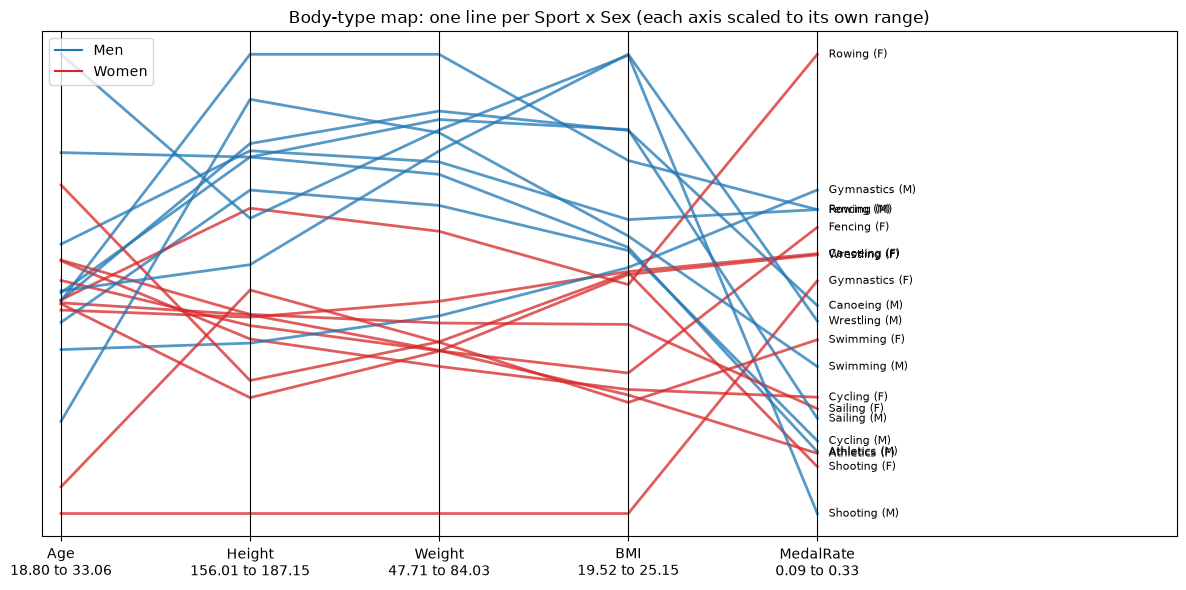

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def plot_parallel(s, min_n=200):
    cols = ["Age", "Height", "Weight", "BMI", "MedalRate"]
    g = (s.groupby(["Sport", "Sex"])
           .agg(Age=("Age", "mean"), Height=("Height", "mean"), Weight=("Weight", "mean"),
                BMI=("BMI", "mean"), MedalRate=("Medalist", "mean"), N=("ID", "nunique"))
           .query("N >= @min_n"))
    z = (g[cols] - g[cols].min()) / (g[cols].max() - g[cols].min())
    color = {"M": "tab:blue", "F": "tab:red"}

    fig, ax = plt.subplots(figsize=(12, 6))
    for (sport, sex), row in z.iterrows():
        ax.plot(range(len(cols)), row.values, color=color[sex], alpha=.75, lw=2)
        ax.text(len(cols) - 1 + .06, row.values[-1], f"{sport} ({sex})", fontsize=8, va="center")
    for x in range(len(cols)):
        ax.axvline(x, color="k", lw=.8)
    # real ranges under each axis, so "0 to 1" is not mistaken for "0 to max"
    ax.set_xticks(range(len(cols)),
                  [f"{c}\n{g[c].min():.2f} to {g[c].max():.2f}" for c in cols])
    ax.set_xlim(-.1, len(cols) + .9)
    ax.set_yticks([])
    ax.plot([], color="tab:blue", label="Men"); ax.plot([], color="tab:red", label="Women")
    ax.legend(loc="upper left")
    ax.set_title("Body-type map: one line per Sport x Sex (each axis scaled to its own range)")
    plt.tight_layout(); plt.show()

plot_parallel(s)

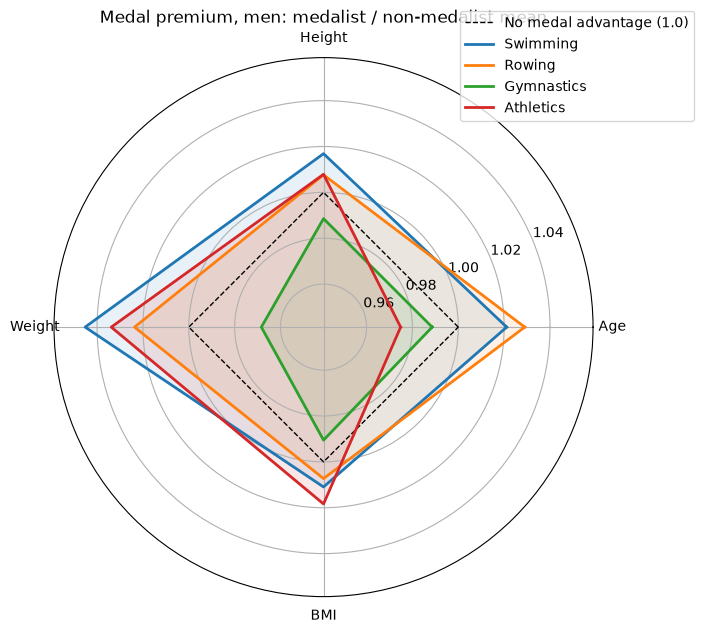

,Swimming,Rowing,Gymnastics,Athletics
Age,1.021,1.029,0.989,0.975
Height,1.017,1.008,0.989,1.008
Weight,1.045,1.024,0.968,1.034
BMI,1.011,1.007,0.991,1.018


In [13]:
import numpy as np
import matplotlib.pyplot as plt

def plot_radar(s, sports=("Swimming", "Rowing", "Gymnastics", "Athletics"), sex="M"):
    cols = ["Age", "Height", "Weight", "BMI"]
    d = s[s.Sex == sex]
    prem = pd.DataFrame({
        sp: (lambda m: m.loc[1] / m.loc[0])(d[d.Sport == sp].groupby("Medalist")[cols].mean())
        for sp in sports})                                  # medalist mean / non-medalist mean
    lim = (prem - 1).abs().max().max() * 1.3

    ang = np.linspace(0, 2 * np.pi, len(cols), endpoint=False).tolist()
    ang += ang[:1]
    fig = plt.figure(figsize=(7, 7))
    ax = plt.subplot(polar=True)
    ax.plot(ang, [1] * len(ang), "k--", lw=1, label="No medal advantage (1.0)")
    for sp in sports:
        v = prem[sp].tolist(); v += v[:1]
        ax.plot(ang, v, lw=2, label=sp)
        ax.fill(ang, v, alpha=.10)
    ax.set_xticks(ang[:-1], cols)
    ax.set_ylim(1 - lim, 1 + lim)
    ax.set_title(f"Medal premium, {'men' if sex == 'M' else 'women'}: medalist / non-medalist mean")
    ax.legend(bbox_to_anchor=(1.2, 1.1))
    plt.show()
    return prem.round(3)

plot_radar(s)

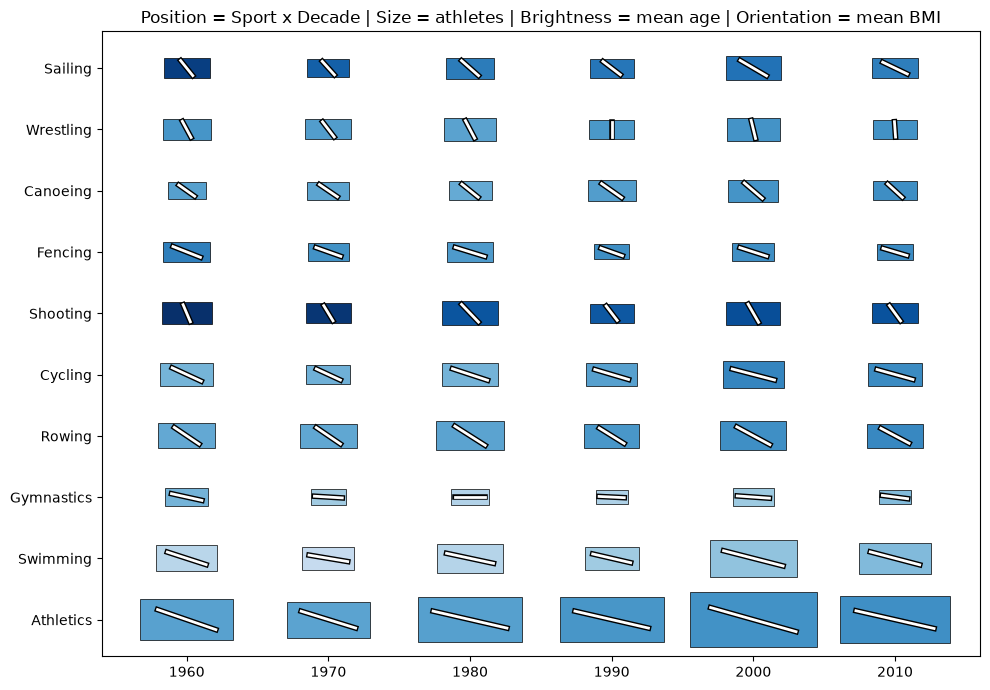

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle

def plot_glyph_grid(s, sports, since=1960):
    s2 = s[s.Year >= since].assign(Decade=lambda d: d.Year // 10 * 10)
    c = (s2.groupby(["Sport", "Decade"])
           .agg(Age=("Age", "mean"), BMI=("BMI", "mean"),
                MedalRate=("Medalist", "mean"), N=("ID", "nunique"))
           .reset_index())
    decades = sorted(c.Decade.unique())
    amin, amax = c.Age.min(), c.Age.max()
    bmin, bmax = c.BMI.min(), c.BMI.max()
    outline = [pe.Stroke(linewidth=4, foreground="k"), pe.Normal()]

    fig, ax = plt.subplots(figsize=(10, 7))
    for _, r in c.iterrows():
        x, y = decades.index(r.Decade), sports.index(r.Sport)
        side = .9 * np.sqrt(r.N / c.N.max())                            # SIZE = athletes
        col = plt.cm.Blues(.25 + .75 * (r.Age - amin) / (amax - amin))  # BRIGHTNESS = mean age
        ax.add_patch(Rectangle((x - side/2, y - side/2), side, side,
                               fc=col, ec="k", lw=.5))
        t = np.radians(90 * (r.BMI - bmin) / (bmax - bmin))             # ORIENTATION = mean BMI
        dx, dy = side * .4 * np.cos(t), side * .4 * np.sin(t)
        ax.plot([x - dx, x + dx], [y + dy, y - dy], color="white", lw=2,
                path_effects=outline)

    ax.set_xlim(-.6, len(decades) - .4)
    ax.set_ylim(-.6, len(sports) - .4)
    ax.set_xticks(range(len(decades)), decades)                         # POSITION x
    ax.set_yticks(range(len(sports)), sports)                           # POSITION y
    ax.set_title("Position = Sport x Decade | Size = athletes | "
                 "Brightness = mean age | Orientation = mean BMI")
    plt.tight_layout()
    plt.show()

plot_glyph_grid(s.to_pandas(), top)

In [14]:
import numpy as np, pandas as pd

# ---- Graph 1 evidence: how much of body-type variation is sport vs sex? (eta squared)
def eta2(d, col, by):
    gm = d[col].mean()
    ssb = d.groupby(by)[col].apply(lambda x: len(x) * (x.mean() - gm) ** 2).sum()
    return ssb / ((d[col] - gm) ** 2).sum()

e = pd.DataFrame({c: {"Sport": eta2(s, c, "Sport"),
                      "Sex": eta2(s, c, "Sex"),
                      "Sport x Sex": eta2(s, c, ["Sport", "Sex"])}
                  for c in ["Age", "Height", "Weight", "BMI"]}).round(3)
print("Share of variance explained (0-1):"); display(e)

# ---- Graph 2 evidence: medal premium, % and Cohen's d, with sample sizes
rows = []
for sp in top:
    for sx in ["M", "F"]:
        d = s[(s.Sport == sp) & (s.Sex == sx)]
        a, b = d[d.Medalist == 1], d[d.Medalist == 0]
        if len(a) < 30: continue
        for c in ["Age", "Height", "Weight", "BMI"]:
            sd = np.sqrt((a[c].var() * (len(a)-1) + b[c].var() * (len(b)-1)) / (len(a)+len(b)-2))
            rows.append((sp, sx, c, len(a), (a[c].mean()/b[c].mean()-1)*100, (a[c].mean()-b[c].mean())/sd))
prem = pd.DataFrame(rows, columns=["Sport", "Sex", "Var", "n_medal", "pct", "d"])
print("Cohen's d (|d| < 0.2 negligible, 0.2-0.5 small, > 0.5 medium+):")
display(prem.pivot_table(index=["Sport", "Sex"], columns="Var", values="d").round(2))

# ---- Graph 3 evidence: women's share and men's height, first vs last decade
s3 = s[s.Year >= 1960].assign(Decade=lambda d: d.Year // 10 * 10)
fem = s3.assign(F=(s3.Sex == "F")).pivot_table(index="Sport", columns="Decade", values="F", aggfunc="mean")
print("Women's share by decade:"); display((fem * 100).round(0))
slope = (s3[s3.Sex == "M"].groupby("Sport")
           .apply(lambda d: np.polyfit(d.Year, d.Height, 1)[0] * 10))
print("Men's height change, cm per decade:"); display(slope.round(2).sort_values())

Share of variance explained (0-1):


,Age,Height,Weight,BMI
Sport,0.238,0.167,0.104,0.109
Sex,0.023,0.232,0.225,0.114
Sport x Sex,0.260,0.407,0.301,0.190


Cohen's d (|d| < 0.2 negligible, 0.2-0.5 small, > 0.5 medium+):


Var              Age   BMI  Height  Weight
Sport      Sex                            
Athletics  F   -0.03  0.15    0.17    0.19
           M   -0.15  0.12    0.17    0.16
Canoeing   F    0.34  0.08    0.30    0.30
           M    0.08  0.30    0.26    0.40
Cycling    F    0.16  0.41    0.29    0.52
           M   -0.05  0.34    0.35    0.53
Fencing    F   -0.01 -0.09    0.22    0.09
           M    0.12  0.13    0.14    0.20
Gymnastics F    0.05 -0.26   -0.21   -0.29
           M   -0.08 -0.15   -0.36   -0.36
Rowing     F    0.10  0.25    0.20    0.29
           M    0.17  0.08    0.16    0.16
Sailing    F    0.05 -0.20    0.22   -0.00
           M    0.11  0.12    0.19    0.20
Shooting   F   -0.10  0.22    0.12    0.26
           M   -0.28  0.05    0.11    0.10
Swimming   F    0.03  0.15    0.47    0.48
           M    0.13  0.15    0.40    0.41
Wrestling  F    0.19 -0.01   -0.01   -0.00
           M    0.07  0.08    0.06    0.09

Women's share by decade:


Decade,1960,1970,1980,1990,2000,2010
Sport,,,,,,
Athletics,23.0,29.0,32.0,37.0,45.0,48.0
Canoeing,17.0,15.0,21.0,23.0,27.0,33.0
Cycling,0.0,0.0,11.0,18.0,28.0,37.0
Fencing,22.0,24.0,24.0,30.0,44.0,51.0
Gymnastics,47.0,50.0,49.0,46.0,50.0,49.0
Rowing,0.0,20.0,34.0,33.0,34.0,37.0
Sailing,0.0,0.0,6.0,22.0,31.0,40.0
Shooting,0.0,2.0,18.0,29.0,36.0,40.0
Swimming,41.0,51.0,41.0,44.0,43.0,48.0


Men's height change, cm per decade:


Sport
Gymnastics   -0.37
Athletics     0.54
Canoeing      0.76
Sailing       0.78
Shooting      0.85
Wrestling     0.87
Cycling       0.91
Fencing       1.07
Swimming      1.37
Rowing        1.41
dtype: float64